# Communicate with a vLLM-served Qwen3-VL-32B model

Sanity-check notebook: pick a sample, overlay bbox annotations on the video, save to disk, then send to the local vLLM server and print the model's answer.

**Prerequisites:** launch the server with `bash bash_scripts/vllm_serving/qwen3vl32b.sh`.

---
# Section 1: V-STaR Dataset

## 1. Load the V-STaR test set

In [1]:
import json
import datasets

dataset = datasets.load_dataset("json", data_files="/projects/torresani-lab/ajay/datasets/V-STaR/V_STaR_test_with_qid.json", split="train")
print(len(dataset))

2094


## 2. Pick a sample and decode its video

In [7]:
import os
import sys
import importlib

import numpy as np
import pandas as pd
import torch
from qwen_vl_utils import fetch_video

sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")
import src.utils.annotation_utils
importlib.reload(src.utils.annotation_utils)
from src.utils.annotation_utils import load_mask_annotations, annotate_frames

# Build the pool of qids the model got wrong (verdict == False) from an eval run's CSV
EVAL_CSV = "/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_zeroshot/2026-05-18_18-35-15/benchmark/evaluation_results.csv"
eval_df = pd.read_csv(EVAL_CSV)
wrong_qids = set(eval_df.loc[~eval_df["verdict"].astype(str).str.lower().eq("true"), "qid"])
wrong_idxs = [i for i, s in enumerate(dataset) if s["qid"] in wrong_qids]
print(f"{len(wrong_idxs)} wrong samples in pool")

# Pick the idx-th wrong sample and decode at fixed token budget
idx = 19
# sample = dataset[wrong_idxs[idx]]
sample = dataset[idx]
print(sample['vid'], sample['qid'])

video_path = os.path.join("/projects/torresani-lab/ajay/datasets/V-STaR/videos", sample['vid'] + ".mp4")
video_input = fetch_video({
    "video": video_path,
    "max_pixels": 512 * 28 * 28,
    "fps": 1,
})
print("video_input:", video_input.shape)

915 wrong samples in pool
5945172741 5945172741_1
video_input: torch.Size([62, 3, 476, 644])


## 3. Overlay annotations on the decoded frames

In [8]:
annotation_root = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/vstar/uniform_sample_cap_768/2026-05-19_19-14-38"
annotation_type = "bbox"  # "bbox" | "mask" | "outline"

# Options
annotate_bbox = True
annotate_frame_nums = False

annotated_input = video_input.clone()

if annotate_bbox:
    annotation_path = os.path.join(annotation_root, "masks", f"{sample['qid']}.json")
    record = load_mask_annotations(annotation_path)
    annotated_input = annotate_frames(annotated_input, record["masks_np"], annotation_type=annotation_type, thickness=2)
    annotated_input = torch.tensor(np.array(annotated_input)).permute(0, 3, 1, 2).to(torch.float32)

# Uniformly sample 16 frames
indices = np.linspace(0, annotated_input.shape[0] - 1, 16, dtype=int)
annotated_input = annotated_input[indices]

if annotate_frame_nums:
    import cv2

    def annotate_frame_numbers(frames: torch.Tensor, scale: float = 2.0, thickness: int = 3) -> torch.Tensor:
        annotated = []
        for i, frame in enumerate(frames):
            arr = cv2.cvtColor(frame.permute(1, 2, 0).numpy().astype(np.uint8), cv2.COLOR_RGB2BGR)
            h, w = arr.shape[:2]
            text = str(i)
            font = cv2.FONT_HERSHEY_SIMPLEX
            (tw, th), baseline = cv2.getTextSize(text, font, scale, thickness)
            x, y = w - tw - 8, h - baseline - 4
            cv2.putText(arr, text, (x, y), font, scale, (0, 0, 255), thickness, cv2.LINE_AA)
            annotated.append(torch.from_numpy(cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1))
        return torch.stack(annotated)

    annotated_input = annotate_frame_numbers(annotated_input)

print("annotated_input:", annotated_input.shape)

annotated_input: torch.Size([16, 3, 476, 644])


## 4. Write the annotated video to disk

In [9]:
from torchcodec.encoders import VideoEncoder

dump_dir = "/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump"
os.makedirs(dump_dir, exist_ok=True)
output_video_path = os.path.join(dump_dir, f"ann_{sample['qid']}.mp4")
VideoEncoder(annotated_input.to(torch.uint8), frame_rate=4).to_file(output_video_path)
print("wrote:", output_video_path)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump/ann_5945172741_1.mp4


## 5. Preview a random annotated frame

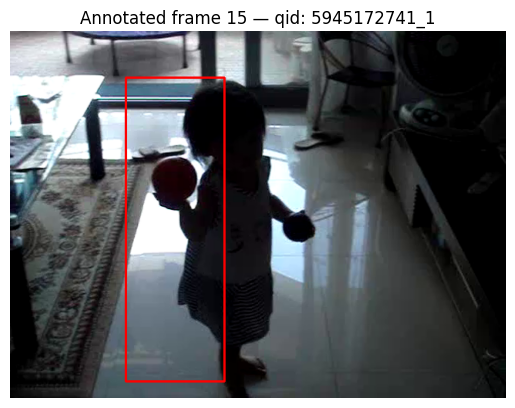

In [10]:
import matplotlib.pyplot as plt

random_idx = np.random.randint(0, annotated_input.shape[0])
any_frame = annotated_input[random_idx].permute(1, 2, 0).numpy().astype(np.uint8)
plt.imshow(any_frame)
plt.title(f"Annotated frame {random_idx} — qid: {sample['qid']}")
plt.axis('off')
plt.show()

## 6. Build the chat request and send to vLLM

In [14]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"
model = "Qwen/Qwen3-VL-32B-Instruct"

# SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/train/openo3_red_bbox_frame_num_v2.md"
SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/rcap/v3_1.md"
with open(SYSTEM_PROMPT_PATH, "r") as f:
    SYSTEM_PROMPT = f.read()

n_frames = annotated_input.shape[0]
# frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

message = [
    {
        "role": "system",
        "content": [{"type": "text", "text": SYSTEM_PROMPT}],
    },
    {
        "role": "user",
        "content": [
            # {"type": "text", "text": frame_prompt + sample['question']},
            # {"type": "text", "text": sample['question']},
            # {"type": "text", "text": "Is the man who watches the other adult man in black wearing a bunny hat?"},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path},
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

In [15]:
import re

# pull the stored prediction for this qid from the eval CSV (CoT, if any, is inline as <think>...</think>)
pred = eval_df.loc[eval_df["qid"] == sample["qid"], "generated_answer"].iloc[0]
cot = re.search(r"<think>(.*?)</think>", str(pred), re.DOTALL)

print(f"QID = {sample['qid']}")
print(f"Question: {sample['question']}")
if cot:
    print(f"Predicted CoT: {cot.group(1).strip()}")
print(f"Generated answer: {pred}")
print(f"Ground truth answer: {sample['answer']}")

QID = 5945172741_1
Question: who does the male adult speak to in the bed?
Generated answer: The male adult speaks to a child in the bed.
Ground truth answer: a male adult speaks to a child in the bed.


## RCAP

In [ ]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message,
    max_tokens=1024,
    temperature=0.7,
    top_p=0.8,
    extra_body={"top_k": 20, "repetition_penalty": 1.0},
    presence_penalty=1.5,
    seed=42,
)
response_text = chat_response.choices[0].message.content
print(response_text)

## Variant-1: RCAP + question (no video) -> Qwen3-VL-32B -> Answer + Reason

In [ ]:
# question = sample['question']
question = "who is sitting above the pink baby seat?"
print(f"Question: {question}")
qa_prompt = (
    "You are given a region caption describing the entity highlighted in a video, "
    "and a question about the video.\n\n"
    f"Region caption: {response_text}\n\n"
    f"Question: {question}\n\n"
    "Think carefully before answering. Then return a JSON object with two fields:\n"
    '- "answer": your answer to the question\n'
    '- "reason": the reasoning behind your answer\n'
)

qa_message = [
    {
        "role": "user",
        "content": [{"type": "text", "text": qa_prompt}],
    },
]

qa_response = client.chat.completions.create(
    model=model,
    messages=qa_message,
    max_tokens=1024,
    temperature=0.7,
    top_p=0.8,
    extra_body={"top_k": 20, "repetition_penalty": 1.0},
    presence_penalty=1.5,
    seed=42,
    response_format={"type": "json_object"},
)
print(qa_response.choices[0].message.content)

## Zeroshot

In [ ]:
# zeroshot verification: send the question + unannotated video directly to the model
# write the raw (unannotated) decoded video to disk, subsampling the same 16 frames
zs_indices = np.linspace(0, video_input.shape[0] - 1, 16, dtype=int)
zs_video_path = os.path.join(dump_dir, f"zeroshot_{sample['qid']}.mp4")
VideoEncoder(video_input[zs_indices].to(torch.uint8), frame_rate=4).to_file(zs_video_path)

# same JSON output format as the rcap-grounded QA: think, then answer + reason
zs_prompt = (
    f"Question: {sample['question']}\n\n"
    "Think carefully before answering. Then return a JSON object with two fields:\n"
    '- "answer": your answer to the question\n'
    '- "reason": the reasoning behind your answer\n'
)

zs_message = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": zs_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + zs_video_path},
                "VIDEO_MAX_PIXELS": 128 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

zs_response = client.chat.completions.create(
    model=model,
    messages=zs_message,
    max_tokens=1024,
    temperature=0.7,
    top_p=0.8,
    extra_body={"top_k": 20, "repetition_penalty": 1.0},
    presence_penalty=1.5,
    seed=42,
    response_format={"type": "json_object"},
)
print(zs_response.choices[0].message.content)

## Variant 2: RCAP + question + annotated video → Qwen3-VL-32B → Answer + Reason

In [ ]:
# Variant 2: region caption + question + annotated video -> reason then answer in JSON
v2_prompt = (
    "You are given a region caption describing the entity highlighted (red bounding box) in the video, "
    "and a question about the video.\n\n"
    f"Region caption: {response_text}\n\n"
    f"Question: {sample['question']}\n\n"
    "Think carefully before answering. Then return a JSON object with two fields:\n"
    '- "answer": your answer to the question\n'
    '- "reason": the reasoning behind your answer\n'
)

v2_message = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": v2_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path},
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

v2_response = client.chat.completions.create(
    model=model,
    messages=v2_message,
    max_tokens=1024,
    temperature=0.7,
    top_p=0.8,
    extra_body={"top_k": 20, "repetition_penalty": 1.0},
    presence_penalty=1.5,
    seed=42,
    response_format={"type": "json_object"},
)
print(v2_response.choices[0].message.content)

## Question-conditioned video summary (no answer)

In [ ]:
# question-conditioned video summary + relevant items, returned as JSON (do NOT answer the question)
summary_prompt = (
    f"Question: {sample['question']}\n\n"
    "Describe the video, emphasizing the parts most relevant to the question above. "
    "Describe only what is visually present; do not answer the question. Focus on the "
    "main elements, not fine details.\n\n"
    "First generate the summary, then from it pick the items needed to answer the question. "
    "Return a JSON object with two fields:\n"
    '- "summary": a concise summary of the video\n'
    '- "items": a list of only the distinct, visually-grounded entities that are relevant '
    "to answering the question. Each item must be a noun (with optional modifiers) that "
    "refers to a single object that can be individually isolated/localized in the frame "
    "(e.g. \"black car\", \"white metal fence\"), not abstract or uncountable concepts "
    "(e.g. \"background\", \"visibility\", \"daytime\").\n"
)

summary_message = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": summary_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path},
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

summary_response = client.chat.completions.create(
    model=model,
    messages=summary_message,
    max_tokens=1024,
    temperature=0.7,
    top_p=0.8,
    extra_body={"top_k": 20, "repetition_penalty": 1.0},
    presence_penalty=1.5,
    seed=42,
    response_format={"type": "json_object"},
)
print(summary_response.choices[0].message.content)

---
# Section 2: Open-o3-Video Dataset (STGR)

## OO3-1. Load dataset and track manifest

In [1]:
import sys
sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

import importlib
import json
import os

import cv2
import numpy as np
import torch
from datasets import load_dataset
from qwen_vl_utils import fetch_video

import src.utils.openo3_utils as openo3_utils
importlib.reload(openo3_utils)
from src.utils.openo3_utils import (
    get_video_path, splice_keyframes,
    load_track_manifest, load_track_masks, masks_to_bboxes,
)

# --- config ---
OO3_JSON    = "/projects/torresani-lab/ajay/datasets/Open-o3-Video/json_data/STGR-SFT.json"
RESULTS_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/uniform_sample_1fps_orig_res_track"

dataset_oo3 = load_dataset("json", data_files=OO3_JSON, split="train")
str_dataset = [s for s in dataset_oo3 if s["task"] == "temporal-spatial free-form QA"]
run_meta, samples = load_track_manifest(RESULTS_DIR)

print(f"Loaded {len(str_dataset)} STGR samples")
print(f"Track manifest: {len(samples)} entries")

Loaded 7047 STGR samples
Track manifest: 7047 entries


## OO3-2. Pick a sample and reconstruct the annotated video

In [9]:
# --- config ---
SAMPLE_IDX    = 0
VIDEO_FPS     = run_meta["config"]["video"]["fps"]
TGT_FRAMES    = 32
ANNOTATE_BBOX = True

sample_oo3 = str_dataset[SAMPLE_IDX]
sample_entry = samples[sample_oo3["id"]]

print(f"Sample {SAMPLE_IDX}  id={sample_oo3['id']}")
print(f"Q: {sample_oo3['question']}")
print(f"A: {sample_oo3['answer']}")
print(f"Concepts: {[c['concept'] for c in sample_entry['concepts']]}")

Sample 0  id=000000
Q: Who is the man seen enjoying a beer with others at the table?
A: The man is Barack Obama. He is shown holding a glass of beer, smiling, and interacting with other people seated at an outdoor table.
Concepts: ['man', 'beer glass']


## OO3-3. Build annotated frame stack (1fps + spliced keyframes + bbox overlays)

In [10]:
# reconstruct augmented frame stack (same as sam3_track.py)
frames = fetch_video({"video": get_video_path(sample_oo3), "fps": VIDEO_FPS})
frames_list = list(frames.permute(0, 2, 3, 1).cpu().numpy().astype("uint8"))
H, W = frames_list[0].shape[:2]
splice_keyframes(sample_oo3, frames_list, H, W)
frames_aug = np.stack(frames_list)  # (T, H, W, 3)
T = len(frames_aug)
print(f"Augmented frame stack: {T} frames, {W}x{H}")

annotated = frames_aug.copy()

if ANNOTATE_BBOX:
    masks_dict = load_track_masks(sample_entry, RESULTS_DIR)
    concepts = list(masks_dict.keys())
    print(f"{len(concepts)} track(s) available: {concepts}")

    # overlay every concept's bbox track onto the frame stack (all red)
    for concept in concepts:
        bboxes = masks_to_bboxes(masks_dict[concept], target_size=(H, W))
        for t, (x1, y1, x2, y2) in enumerate(bboxes.astype(int)):
            if x2 > x1 and y2 > y1:
                cv2.rectangle(annotated[t], (x1, y1), (x2, y2), color=(255, 0, 0), thickness=2)

# subsample to TGT_FRAMES
indices = np.linspace(0, T - 1, TGT_FRAMES, dtype=int)
annotated_input_oo3 = torch.tensor(annotated[indices]).permute(0, 3, 1, 2).to(torch.float32)
print(f"annotated_input: {annotated_input_oo3.shape}")

Augmented frame stack: 66 frames, 448x252
2 track(s) available: ['man', 'beer glass']
annotated_input: torch.Size([32, 3, 252, 448])


## OO3-4. Preview a random annotated frame

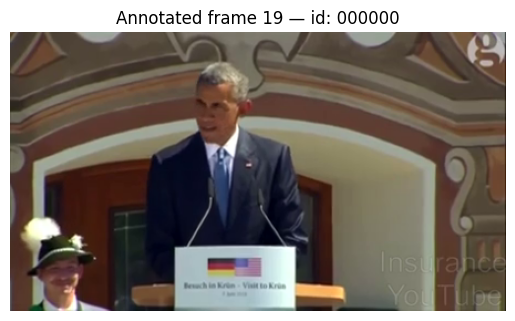

In [11]:
import matplotlib.pyplot as plt

random_idx = np.random.randint(0, annotated_input_oo3.shape[0])
any_frame = annotated_input_oo3[random_idx].permute(1, 2, 0).numpy().astype(np.uint8)
plt.imshow(any_frame)
plt.title(f"Annotated frame {random_idx} — id: {sample_oo3['id']}")
plt.axis('off')
plt.show()

## OO3-5. Save annotated video to disk

In [12]:
from torchcodec.encoders import VideoEncoder

dump_dir = "/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump"
os.makedirs(dump_dir, exist_ok=True)
output_video_path_oo3 = os.path.join(dump_dir, f"oo3_ann_{sample_oo3['id']}.mp4")
VideoEncoder(annotated_input_oo3.to(torch.uint8), frame_rate=4).to_file(output_video_path_oo3)
print("wrote:", output_video_path_oo3)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump/oo3_ann_000000.mp4


## OO3-6. Build the chat request and send to vLLM

In [13]:
# def create_user_prompt(video_summary, question, concept_captions, answer=None):
#     prompt = f"Video summary: {video_summary}\n"
#     prompt += f"Question: {question}\n"
#     prompt += "Relevant concepts and their captions:\n"
#     for concept, caption in concept_captions.items():
#         prompt += f"- {concept}: {caption}\n"
#     if answer is not None:
#         prompt += f"Answer: {answer}\n"
#     return prompt
def create_user_prompt(video_summary, question, concept_captions, answer=None):
    prompt = f"{video_summary}\n"
    prompt += "Red bounding box annotated objects/entities in the video:\n"
    for concept, caption in concept_captions.items():
        prompt += f"- {concept}: {caption}\n"
    prompt += f"Question: {question}\n"
    if answer is not None:
        prompt += f"Ground Truth Answer: {answer}\n"
    return prompt

# load the PLM rcap outputs (video summary + per-concept captions) for the current sample
RCAP_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/openo3_str_plm_rcap"
rcap = json.load(open(os.path.join(RCAP_DIR, "samples", f"{sample_oo3['id']}.json")))

user_prompt = create_user_prompt(
    video_summary=rcap["video_summary"],
    question=sample_oo3["question"],
    concept_captions=rcap["concept_captions"],
    answer=sample_oo3["answer"],
)
print(user_prompt)

The video features former President Barack Obama and German Chancellor Angela Merkel addressing a crowd of people in traditional German dress. The video cuts to President Obama addressing the crowd from a podium, then to him sitting at a table with others, drinking beer and eating food.
The video begins with President Obama and Chancellor Merkel walking through a crowd of people in traditional German dress. The video cuts to President Obama standing at a podium, addressing the crowd. The video cuts to a shot of the crowd clapping. The video cuts back to President Obama at the podium, then to him sitting at a table with others, drinking beer and eating food.
The video features a crowd of people in traditional German dress, as well as President Obama and Chancellor Merkel.
Red bounding box annotated objects/entities in the video:
- man: The man in white clothes holds up the glass and talks, then sits down and talks to the woman in the hat.
- beer glass: A glass of beer is being held by a

In [14]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"
model = "Qwen/Qwen3-VL-32B-Instruct"

SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/cot/v8.md"
with open(SYSTEM_PROMPT_PATH, "r") as f:
    SYSTEM_PROMPT = f.read()

n_frames = annotated_input_oo3.shape[0]
frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

message_oo3 = [
    {
        "role": "system",
        "content": [{"type": "text", "text": SYSTEM_PROMPT}],
    },
    {
        "role": "user",
        "content": [
            {"type": "text", "text": frame_prompt + user_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path_oo3},
                # "VIDEO_MIN_PIXELS": 512 * 28 * 28,
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

In [ ]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message_oo3,
    max_tokens=1024,
    temperature=0.7,
    top_p=0.8,
    extra_body={"top_k": 20, "repetition_penalty": 1.0},
    presence_penalty=1.5,
    seed=42,
)
response_text = chat_response.choices[0].message.content
print(response_text)

In [ ]:
print(f"Question: {sample_oo3['question']}")
print(f"Ground truth answer: {sample_oo3['answer']}")
print(f"CoT: {sample_oo3['reasoning_process']}")

print(f"Sample {SAMPLE_IDX}  id={sample_oo3['id']}")
print(f"Q: {sample_oo3['question']}")
print(f"A: {sample_oo3['answer']}")
print(f"CoT: {sample_oo3['reasoning_process']}")
print(f"Concepts: {[c['concept'] for c in sample_entry['concepts']]}")

---
# Section 3: Open-o3-Video Region Captioning (single annotated entity)

Pick one tracked concept, overlay only its bbox across frames, and ask the model to caption what is happening to that highlighted entity. Reuses the dataset, track manifest, and helpers loaded in Section 2.

In [17]:
import sys
sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

import importlib
import json
import os

import cv2
import numpy as np
import torch
from datasets import load_dataset
from qwen_vl_utils import fetch_video

import src.utils.openo3_utils as openo3_utils
importlib.reload(openo3_utils)
from src.utils.openo3_utils import (
    get_video_path, splice_keyframes,
    load_track_manifest, load_track_masks, masks_to_bboxes,
)

# --- config ---
OO3_JSON    = "/projects/torresani-lab/ajay/datasets/Open-o3-Video/json_data/STGR-SFT.json"
RESULTS_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/uniform_sample_1fps_orig_res_track"

dataset_oo3 = load_dataset("json", data_files=OO3_JSON, split="train")
str_dataset = [s for s in dataset_oo3 if s["task"] == "temporal-spatial free-form QA"]
run_meta, samples = load_track_manifest(RESULTS_DIR)

print(f"Loaded {len(str_dataset)} STGR samples")
print(f"Track manifest: {len(samples)} entries")

Loaded 7047 STGR samples
Track manifest: 7047 entries


## RCAP-1. Pick a sample and one concept to annotate

In [37]:
# --- config ---
RCAP_SAMPLE_IDX = 55
CONCEPT_IDX     = 0      # which tracked concept to highlight
VIDEO_FPS       = run_meta["config"]["video"]["fps"]
TGT_FRAMES      = 32

rcap_sample = str_dataset[RCAP_SAMPLE_IDX]
rcap_entry  = samples[rcap_sample["id"]]

# load this sample's tracks and pick the single concept to annotate
masks_dict_rcap = load_track_masks(rcap_entry, RESULTS_DIR)
concept = list(masks_dict_rcap.keys())[CONCEPT_IDX]

print(f"Sample {RCAP_SAMPLE_IDX}  id={rcap_sample['id']}")
print(f"Available concepts: {list(masks_dict_rcap.keys())}")
print(f"Captioning concept: {concept!r}")

Sample 55  id=000070
Available concepts: ['car', 'man']
Captioning concept: 'car'


## RCAP-2. Build the frame stack with only that concept's bbox overlaid

In [38]:
# reconstruct augmented frame stack (1fps + spliced keyframes), same as Section 2
frames = fetch_video({"video": get_video_path(rcap_sample), "fps": VIDEO_FPS})
frames_list = list(frames.permute(0, 2, 3, 1).cpu().numpy().astype("uint8"))
H, W = frames_list[0].shape[:2]
splice_keyframes(rcap_sample, frames_list, H, W)
frames_aug = np.stack(frames_list)  # (T, H, W, 3)
T = len(frames_aug)

# overlay only the chosen concept's bbox track (red)
annotated = frames_aug.copy()
bboxes = masks_to_bboxes(masks_dict_rcap[concept], target_size=(H, W))
for t, (x1, y1, x2, y2) in enumerate(bboxes.astype(int)):
    if x2 > x1 and y2 > y1:
        cv2.rectangle(annotated[t], (x1, y1), (x2, y2), color=(255, 0, 0), thickness=2)

# subsample to TGT_FRAMES
indices = np.linspace(0, T - 1, TGT_FRAMES, dtype=int)
annotated_input_rcap = torch.tensor(annotated[indices]).permute(0, 3, 1, 2).to(torch.float32)
print(f"annotated_input: {annotated_input_rcap.shape}")

annotated_input: torch.Size([32, 3, 252, 476])


## RCAP-3. Save annotated video to disk

In [39]:
from torchcodec.encoders import VideoEncoder

dump_dir = "/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump"
os.makedirs(dump_dir, exist_ok=True)
concept_slug = concept.replace(" ", "_")
output_video_path_rcap = os.path.join(dump_dir, f"rcap_{rcap_sample['id']}_{concept_slug}.mp4")
VideoEncoder(annotated_input_rcap.to(torch.uint8), frame_rate=4).to_file(output_video_path_rcap)
print("wrote:", output_video_path_rcap)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump/rcap_000070_car.mp4


In [40]:
from src.utils.notebook_utils import show_video
show_video(video_path=output_video_path_rcap, fps=4)

'/tmp/_preview.mp4'

## RCAP-4. Build the chat request and send to vLLM

In [41]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"
model = "Qwen/Qwen3-VL-32B-Instruct"

# SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/rcap/v4.md" -> biases caption; guardrails make the model simply caption wrong regions
SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/rcap/v3_4.md"
with open(SYSTEM_PROMPT_PATH, "r") as f:
    rcap_prompt = f.read()
    
n_frames = annotated_input_rcap.shape[0]
# frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

message_rcap = [
    {
        "role": "user",
        "content": [
            # {"type": "text", "text": rcap_prompt + "\n\nQuestion: " + rcap_sample["question"]},
            {"type": "text", "text": rcap_prompt + "\n\nQuestion: " + rcap_sample["question"] + "\n\nRelevant concept: " + concept},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path_rcap},
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

In [ ]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message_rcap,
    max_tokens=1024,
    temperature=0.7,
    top_p=0.8,
    extra_body={"top_k": 20, "repetition_penalty": 1.0},
    presence_penalty=1.5,
    seed=42,
)
response_text = chat_response.choices[0].message.content
print(f"Concept: {concept}\n")
print(response_text)

In [36]:
# For comparison: PLM's caption for the same concept
RCAP_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/openo3_str_plm_rcap"
plm_rcap = json.load(open(os.path.join(RCAP_DIR, "samples", f"{rcap_sample['id']}.json")))

print(f"Concept: {concept}\n")
print(plm_rcap["concept_captions"][concept])
print(f"\n\nOriginal question: {rcap_sample['question']}")
print(f"Ground truth answer: {rcap_sample['answer']}")

Concept: man

A man is cleaning the car with a cloth and cleaning solution. he is wearing a cap and a t-shirt. he is cleaning the car from the outside and inside. he is cleaning the car with a cloth and a vacuum cleaner. he is cleaning the car from all the sides.


Original question: What is the color of the car that the men are washing?
Ground truth answer: The men are washing a black car. It is shown being washed and detailed by several people.


---
# Section 4: Open-o3-Video — caption all concepts, then build a synthetic structured CoT

Same per-concept region captioning as Section 3, but looped over **every** tracked concept (one overlaid concept at a time). The generated region captions are then fed — together with a video summary — into the CoT prompt to produce a synthetic structured chain-of-thought trace.

In [1]:
import sys
sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

import importlib
import json
import os

import cv2
import numpy as np
import torch
from datasets import load_dataset
from qwen_vl_utils import fetch_video

import src.utils.openo3_utils as openo3_utils
from src.utils.notebook_utils import show_video
importlib.reload(openo3_utils)
from src.utils.openo3_utils import (
    get_video_path, splice_keyframes,
    load_track_manifest, load_track_masks, masks_to_bboxes,
)

# --- config ---
OO3_JSON    = "/projects/torresani-lab/ajay/datasets/Open-o3-Video/json_data/STGR-SFT.json"
RESULTS_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/uniform_sample_1fps_orig_res_track"

dataset_oo3 = load_dataset("json", data_files=OO3_JSON, split="train")
str_dataset = [s for s in dataset_oo3 if s["task"] == "temporal-spatial free-form QA"]
run_meta, samples = load_track_manifest(RESULTS_DIR)

print(f"Loaded {len(str_dataset)} STGR samples")
print(f"Track manifest: {len(samples)} entries")

Loaded 7047 STGR samples
Track manifest: 7047 entries


## SEC4-1. Pick a sample (all its concepts will be captioned)

In [10]:
# --- config ---
SEC4_SAMPLE_IDX = 98
VIDEO_FPS       = run_meta["config"]["video"]["fps"]
TGT_FRAMES      = 32

sec4_sample = str_dataset[SEC4_SAMPLE_IDX]
sec4_entry  = samples[sec4_sample["id"]]

# load this sample's tracks; every concept will be captioned in turn
masks_dict_sec4 = load_track_masks(sec4_entry, RESULTS_DIR)
sec4_concepts = list(masks_dict_sec4.keys())

print(f"Sample {SEC4_SAMPLE_IDX}  id={sec4_sample['id']}")
print(f"Q: {sec4_sample['question']}")
print(f"A: {sec4_sample['answer']}")
print(f"Concepts to caption: {sec4_concepts}")

# decode the augmented frame stack once (1fps + spliced keyframes); reused per concept
frames = fetch_video({"video": get_video_path(sec4_sample), "fps": VIDEO_FPS})
frames_list = list(frames.permute(0, 2, 3, 1).cpu().numpy().astype("uint8"))
H, W = frames_list[0].shape[:2]
splice_keyframes(sec4_sample, frames_list, H, W)
frames_aug = np.stack(frames_list)  # (T, H, W, 3)
T = len(frames_aug)
print(f"Augmented frame stack: {T} frames, {W}x{H}")

indices = np.linspace(0, T - 1, TGT_FRAMES, dtype=int)
sampled_frames_aug = frames_aug[indices]
show_video(sampled_frames_aug)

Sample 98  id=000127
Q: What brand of multi-purpose solution is shown in the video?
A: The video shows a bottle of Renew multi-purpose solution, which is used for cleaning contact lenses.
Concepts to caption: ['bottle']
Augmented frame stack: 89 frames, 448x252


'/tmp/_preview.mp4'

## SEC4-2. Loop over all concepts: overlay one bbox at a time, caption it

In [5]:
from openai import OpenAI
from torchcodec.encoders import VideoEncoder

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"
model = "Qwen/Qwen3-VL-32B-Instruct"
client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

dump_dir = "/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump"
os.makedirs(dump_dir, exist_ok=True)

RCAP_SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/rcap/v3_4.md"
with open(RCAP_SYSTEM_PROMPT_PATH, "r") as f:
    rcap_prompt = f.read()

# caption each concept in turn: overlay only its bbox, save the clip, ask the model
sec4_concept_captions = {}
for concept in sec4_concepts:
    # overlay only this concept's bbox track (red)
    annotated = frames_aug.copy()
    bboxes = masks_to_bboxes(masks_dict_sec4[concept], target_size=(H, W))
    for t, (x1, y1, x2, y2) in enumerate(bboxes.astype(int)):
        if x2 > x1 and y2 > y1:
            cv2.rectangle(annotated[t], (x1, y1), (x2, y2), color=(255, 0, 0), thickness=2)

    # subsample to TGT_FRAMES and write the annotated clip to disk
    indices = np.linspace(0, T - 1, TGT_FRAMES, dtype=int)
    show_video(annotated[indices])
    annotated_input = torch.tensor(annotated[indices]).permute(0, 3, 1, 2).to(torch.float32)
    concept_slug = concept.replace(" ", "_")
    clip_path = os.path.join(dump_dir, f"sec4_{sec4_sample['id']}_{concept_slug}.mp4")
    VideoEncoder(annotated_input.to(torch.uint8), frame_rate=4).to_file(clip_path)

    # ask the model to caption the highlighted concept
    message = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": rcap_prompt + "\n\nQuestion: " + sec4_sample["question"] + "\n\nRelevant concept: " + concept},
                {
                    "type": "video_url",
                    "video_url": {"url": "file://" + clip_path},
                    "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                    "fps": 1,
                },
            ],
        },
    ]
    resp = client.chat.completions.create(
        model=model,
        messages=message,
        max_tokens=1024,
        temperature=0.7,
        top_p=0.8,
        extra_body={"top_k": 20, "repetition_penalty": 1.0},
        presence_penalty=1.5,
        seed=42,
    )
    sec4_concept_captions[concept] = resp.choices[0].message.content
    print(f"=== {concept} ===")
    print(sec4_concept_captions[concept])
    print()

APIConnectionError: Connection error.

## SEC4-3. Build the synthetic structured CoT from the generated region captions

In [18]:
def create_user_prompt(question, concept_captions, answer=None):
    prompt = "Red bounding box annotated objects/entities in the video:\n"
    for concept, caption in concept_captions.items():
        prompt += f"- {concept}: {caption}\n"
    prompt += f"Question: {question}\n"
    if answer is not None:
        prompt += f"Ground Truth Answer: {answer}\n"
    return prompt

# add a universally irrelevant entity+caption pair to the prompt
# sec4_concept_captions["pillow"] = "the pillow is brown/black in color"

# per-concept captions come from the SEC4-2 loop above
cot_user_prompt = create_user_prompt(
    question=sec4_sample["question"],
    concept_captions=sec4_concept_captions,
    # answer=sec4_sample["answer"],
)
print(cot_user_prompt)

# CoT system prompt
COT_SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/cot/v14_only_rcap_estb_rln_no_gt_calib.md"
with open(COT_SYSTEM_PROMPT_PATH, "r") as f:
    COT_SYSTEM_PROMPT = f.read()

# the annotated video shown to the CoT model overlays every concept's bbox (all red), as in Section 2
annotated_all = frames_aug.copy()
for concept in sec4_concepts:
    bboxes = masks_to_bboxes(masks_dict_sec4[concept], target_size=(H, W))
    for t, (x1, y1, x2, y2) in enumerate(bboxes.astype(int)):
        if x2 > x1 and y2 > y1:
            cv2.rectangle(annotated_all[t], (x1, y1), (x2, y2), color=(255, 0, 0), thickness=2)
indices = np.linspace(0, T - 1, TGT_FRAMES, dtype=int)
annotated_input_all = torch.tensor(annotated_all[indices]).permute(0, 3, 1, 2).to(torch.float32)
cot_video_path = os.path.join(dump_dir, f"sec4_cot_{sec4_sample['id']}.mp4")
VideoEncoder(annotated_input_all.to(torch.uint8), frame_rate=4).to_file(cot_video_path)

n_frames = annotated_input_all.shape[0]
frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

cot_message = [
    {
        "role": "system",
        "content": [{"type": "text", "text": COT_SYSTEM_PROMPT}],
    },
    {
        "role": "user",
        "content": [
            {"type": "text", "text": cot_user_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + cot_video_path},
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

cot_response = client.chat.completions.create(
    model=model,
    messages=cot_message,
    max_tokens=1024,
    temperature=0.7,
    top_p=0.8,
    extra_body={"top_k": 20, "repetition_penalty": 1.0},
    presence_penalty=1.5,
    seed=42,
)
print("=" * 50)
print(cot_response.choices[0].message.content)

Red bounding box annotated objects/entities in the video:
- man: <caption>The man, wearing a blue long-sleeved work uniform and a white cap, is seen handling construction materials. He initially stands near bags of sand-cement plaster, using a tool to break open one of the bags. He then bends down to pour the contents into a large white bucket labeled "Saveto." After mixing the material, he applies it to a concrete block wall using a trowel, spreading the plaster evenly across the surface. Throughout the sequence, he remains focused on the task, moving methodically from preparing the mixture to applying it to the wall. His attire remains consistent, with the blue uniform covering his torso and legs, and the white cap on his head.</caption>
Question: What is the man applying the plaster to the wall wearing?

The red bounding box draws my attention to the man in the video. I observe that he is wearing a blue long-sleeved work uniform that covers his torso and legs. On his head, he has a 